# 주변 시설 수에 따라 사고유형의 비중이 어떻게 달라질까?

서울 사고누적지점의 2023~2025년 사망·중상사고와 지점 중심 반경 1 km의 시설 수를 연결한 CSV를 사용한다. 여덟 시설 지표 각각에 대해 시설이 적은 지점, 중간인 지점, 많은 지점을 비교한다.

여기서 **사고유형 비중**은 한 구간에서 발생한 특정 유형의 사고 건수를 그 구간의 전체 사고 건수로 나눈 값이다. 먼저 과속방지턱을 예로 분자와 분모를 확인한 뒤, 같은 계산을 여덟 시설 지표의 대분류와 세부유형에 적용한다.

[02 · 사고다발 지점 주변 시설 집계](02_count_nearby_facilities.ipynb)의 반경 1,000 m 통합 CSV에서 시작한다.

## 1. 분석 대상과 필요한 열 확인하기

한 행은 사고 한 건이다. 자치구·지점명·중심 좌표로 지점을 구분한다. 파일명의 1000m는 시설을 집계한 반경을 뜻한다. 횡단보도는 대로변 횡단보도 링크 수, 어린이보호구역은 대상시설 수, 방지턱은 요철형과 이미지형의 합계다.

카메라는 네 지표로 비교한다. **무인단속 합계**는 주정차 외 단속 장비 대수와 불법주정차 단속지점 수의 합이다. **불법주정차 CCTV**는 이 합계에 포함돼 있고, **교통관리센터 CCTV**는 소통 관제 장비를 센다. **전체 CCTV**는 무인단속 합계에 교통관리센터 CCTV를 더한 값이다. 02번 10단계에서 검산한 CSV를 읽고 두 합계가 각 구성 항목과 일치하는지 확인한다.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

filename = "사고_분석용_주변시설_1000m_CCTV보완.csv"
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/processed" / filename).is_file())
facility_columns = {
    "신호등_수량": "신호등",
    "어린이보호구역_대상시설수": "어린이보호구역",
    "무인교통단속카메라_집계수": "무인단속 합계",
    "불법주정차CCTV_지점수": "불법주정차 CCTV",
    "교통관리센터CCTV_대수": "교통관리센터 CCTV",
    "전체CCTV_집계수": "전체 CCTV",
    "대로변횡단보도_링크수": "대로변횡단보도",
    "과속방지턱_개수": "과속방지턱",
}
facilities = list(facility_columns.values())
site_key = ["자치구", "지점명", "지점위도", "지점경도"]
columns = [*site_key, "지점사고건수", "연도", "사고등급", "사고유형_대분류", "사고유형_세부", "주정차외_무인단속카메라_대수", *facility_columns]
events = pd.read_csv(root / "data/processed" / filename, usecols=columns, dtype=dict.fromkeys(site_key, "string"))
events = events.rename(columns=facility_columns)

expected_total = events["불법주정차 CCTV"] + events["주정차외_무인단속카메라_대수"]
assert events["무인단속 합계"].eq(expected_total).all(), "CCTV 단속 합계의 구성 확인 필요"
assert events["전체 CCTV"].eq(expected_total + events["교통관리센터 CCTV"]).all(), "전체 CCTV 합계 확인 필요"
print(f"{filename} · 단속 합계와 전체 CCTV 집계수 {len(events):,}행 확인")

assert events.notna().all().all()
assert events[facilities].ge(0).all().all() and events[facilities].mod(1).eq(0).all().all()
print(f"{events['연도'].min()}~{events['연도'].max()}년 · {len(events[site_key].drop_duplicates())}개 지점 · {len(events):,}건")
display(events["사고등급"].value_counts().rename("사고 건수").to_frame())
display(events.head(3))

사고_분석용_주변시설_1000m_CCTV보완.csv · 단속 합계와 전체 CCTV 집계수 4,564행 확인
2023~2025년 · 327개 지점 · 4,564건


,사고 건수
사고등급,
중상사고,4460
사망사고,104


,자치구,지점명,지점위도,지점경도,연도,사고등급,사고유형_대분류,사고유형_세부,지점사고건수,신호등,어린이보호구역,주정차외_무인단속카메라_대수,불법주정차 CCTV,교통관리센터 CCTV,대로변횡단보도,과속방지턱,무인단속 합계,전체 CCTV
0,강남구,수서역앞교차로,37.487374913895344,127.10170388356964,2023,중상사고,차대차,차대차-기타,27,272,6,5,15,3,45,54,20,23
1,강남구,수서역앞교차로,37.487374913895344,127.10170388356964,2023,중상사고,차대차,측면직각충돌,27,272,6,5,15,3,45,54,20,23
2,강남구,수서역앞교차로,37.487374913895344,127.10170388356964,2023,중상사고,차대차,추돌(진행중),27,272,6,5,15,3,45,54,20,23


## 2. 사고유형별 건수와 비중 보기

아래 코드 셀 하나만 실행하면 통합 CSV에서 대분류와 세부유형별 사고 건수를 많은 순으로 확인할 수 있다. 한 행은 사고 한 건이며, 두 표 모두 비중의 분모는 전체 사고 건수다. 세부유형은 전체 사고의 1% 미만인 항목을 ‘기타(소수 유형)’으로 묶는다. 같은 묶음을 6단계의 비중 비교와 7단계 히트맵에도 사용한다. 기준값을 바꾸려면 아래 셀의 min_share_pct를 수정하고 이 셀부터 다시 실행한다.

In [2]:
from collections import Counter
import csv
from pathlib import Path
from IPython.display import Markdown, display

min_share_pct = 1.0
relative_path = Path("data/processed/사고_분석용_주변시설_1000m_CCTV보완.csv")
csv_path = next(folder / relative_path for folder in (Path.cwd(), *Path.cwd().parents)
                if (folder / relative_path).is_file())
major_col, detail_col = "사고유형_대분류", "사고유형_세부"
major_counts = Counter()
detail_counts = Counter()
with csv_path.open(encoding="utf-8-sig", newline="") as file:
    for crash in csv.DictReader(file):
        major_name, detail_name = crash[major_col] or "미상", crash[detail_col] or "미상"
        major_counts[(major_name,)] += 1
        detail_counts[(major_name, detail_name)] += 1

total_crashes = sum(major_counts.values())
display_counts = Counter()
grouped_detail_labels = {}
small_types = []
for source_key, count in detail_counts.most_common():
    display_key = source_key
    if 100 * count / total_crashes < min_share_pct:
        small_types.append(f"{source_key[1]} {count}건")
        display_key = ("대분류 통합", "기타(소수 유형)")
    display_counts[display_key] += count
    grouped_detail_labels[source_key] = display_key[1]
assert sum(display_counts.values()) == total_crashes

def show_counts(fields, counts):
    headers = [*fields, "건수", "전체 사고 중 비중"]
    table = [" | ".join(headers), " | ".join(["---"] * len(headers))]
    for labels, count in counts.most_common():
        table.append(" | ".join([*labels, f"{count:,}", f"{count / total_crashes:.2%}"]))
    display(Markdown("\n".join(table)))

print(f"전체 사고 {total_crashes:,}건")
show_counts([major_col], major_counts)
show_counts([major_col, detail_col], display_counts)
if small_types:
    print(f"기타(소수 유형)에 포함된 항목 · 전체 사고의 {min_share_pct:g}% 미만")
    print(", ".join(small_types))

전체 사고 4,564건


사고유형_대분류 | 건수 | 전체 사고 중 비중
--- | --- | ---
차대차 | 3,118 | 68.32%
차대사람 | 1,203 | 26.36%
차량단독 | 243 | 5.32%

사고유형_대분류 | 사고유형_세부 | 건수 | 전체 사고 중 비중
--- | --- | --- | ---
차대차 | 측면직각충돌 | 1,315 | 28.81%
차대차 | 차대차-기타 | 1,156 | 25.33%
차대사람 | 횡단중 | 575 | 12.60%
차대차 | 추돌(진행중) | 439 | 9.62%
차대사람 | 차대사람-기타 | 421 | 9.22%
차량단독 | 차량단독-기타 | 225 | 4.93%
차대차 | 정면충돌 | 194 | 4.25%
차대사람 | 차도통행중 | 98 | 2.15%
차대사람 | 보도통행중 | 97 | 2.13%
대분류 통합 | 기타(소수 유형) | 44 | 0.96%

기타(소수 유형)에 포함된 항목 · 전체 사고의 1% 미만
후진중추돌 14건, 길가장자리구역통행중 12건, 공작물추돌 11건, 전도 6건, 도로외이탈(추락) 1건


## 3. 시설별로 지점을 세 구간으로 나누기

사고가 많은 지점에서는 같은 시설 수가 여러 행에 반복된다. 먼저 지점별 시설 수가 일관되는지 확인한 뒤 지점당 한 행만 남긴다. 이 지점들의 시설 수에서 하위 1/3과 2/3에 해당하는 값을 경계로 삼는다. 경계에 같은 값이 있으면 모두 같은 구간에 넣어, 구간별 지점 수는 조금씩 달라질 수 있다.

**전체 CCTV**에도 지점 기준 삼분위를 적용한다. **교통관리센터 CCTV**는 0대인 지점이 많아 삼분위 경계가 겹치므로 **0대 = 적음, 1대 = 중간, 2대 이상 = 많음**으로 나눈다.

In [3]:
by_site = events.groupby(site_key)
assert by_site[[*facilities, "지점사고건수"]].nunique().eq(1).all().all()
sites = events.drop_duplicates(site_key).set_index(site_key)[[*facilities, "지점사고건수"]]
assert by_site.size().reindex(sites.index).eq(sites["지점사고건수"]).all()
display(sites[facilities].describe().loc[["min", "50%", "max"]].rename(
    index={"min": "최소", "50%": "중앙값", "max": "최대"}))

,신호등,어린이보호구역,무인단속 합계,불법주정차 CCTV,교통관리센터 CCTV,전체 CCTV,대로변횡단보도,과속방지턱
최소,117.0,1.0,12.0,4.0,0.0,12.0,13.0,19.0
중앙값,464.0,11.0,54.0,37.0,0.0,55.0,87.0,134.0
최대,872.0,30.0,136.0,105.0,7.0,136.0,255.0,399.0


In [4]:
levels = ["적음", "중간", "많음"]
site_groups = {}
summaries = []
for facility in facilities:
    if facility == "교통관리센터 CCTV":
        groups = pd.cut(sites[facility], bins=[-1, 0, 1, np.inf], labels=levels)
    else:
        groups = pd.qcut(sites[facility], q=3, labels=levels)
    assert groups.value_counts().reindex(levels, fill_value=0).gt(0).all(), f"{facility}의 빈 구간을 확인하세요."
    site_groups[facility] = groups
    bounds = sites.groupby(groups.rename("구간"), observed=True).agg(
        시설수_최소=(facility, "min"), 시설수_최대=(facility, "max"),
        지점수=(facility, "size"), 사고건수=("지점사고건수", "sum"),
    )
    summaries.append(bounds.assign(시설=facility).reset_index())

group_sizes = pd.concat(summaries, ignore_index=True).set_index(["시설", "구간"])
assert group_sizes.groupby(level="시설")["지점수"].sum().eq(len(sites)).all()
assert group_sizes.groupby(level="시설")["사고건수"].sum().eq(len(events)).all()
display(group_sizes)

시설수_최소  시설수_최대  지점수  사고건수
시설          구간                           
신호등         적음     117     399  109  1476
            중간     400     527  109  1468
            많음     528     872  109  1620
어린이보호구역     적음       1       9  131  1864
            중간      10      14  102  1387
            많음      15      30   94  1313
무인단속 합계     적음      12      46  118  1586
            중간      47      65  105  1439
            많음      66     136  104  1539
불법주정차 CCTV  적음       4      29  115  1556
            중간      30      46  105  1424
            많음      47     105  107  1584
교통관리센터 CCTV 적음       0       0  195  2706
            중간       1       1   59   791
            많음       2       7   73  1067
전체 CCTV     적음      12      46  112  1486
            중간      47      65  106  1467
            많음      66     136  109  1611
대로변횡단보도     적음      13      74  109  1445
            중간      75     106  114  1585
            많음     107     255  104  1534
과속방지턱       적음      19     101  110  1549
            중간     102     161  108  1453
            많음     162     399  109  1562

표의 최소·최대는 각 구간에서 실제 관측한 시설 수다. 시설마다 구간을 따로 만들므로 한 지점이 신호등에서는 ‘많음’, 방지턱에서는 ‘적음’에 속할 수 있다.

## 4. 과속방지턱을 예로 사고 건수에서 비중 계산하기

각 사고의 자치구·지점명·중심 좌표로 그 지점의 방지턱 구간을 찾는다. 첫 표에서 사고 건수를 세고, 둘째 표에서 각 행을 그 행의 전체 사고 건수로 나눈다. `example_facility`를 바꾸면 다른 시설에도 같은 과정을 적용할 수 있다.

In [5]:
example_facility = "과속방지턱"
groups_by_site = pd.DataFrame(site_groups)
crash_groups = events[site_key].join(groups_by_site, on=site_key, validate="many_to_one")
assert crash_groups[facilities].notna().all().all()
display(crash_groups[["지점명", example_facility]].head())

,지점명,과속방지턱
0,수서역앞교차로,적음
1,수서역앞교차로,적음
2,수서역앞교차로,적음
3,수서역앞교차로,적음
4,수서역앞교차로,적음


이제 한 행은 사고 한 건이고 각 사고에 시설 구간이 붙었다. 예시 시설로 교차표를 만든다. 첫 표의 ‘전체 사고건수’가 둘째 표에서 같은 행의 분모다.

In [6]:
def count_types(facility, type_column):
    groups = crash_groups[facility].rename("구간")
    counts = pd.crosstab(groups, events[type_column]).reindex(levels, fill_value=0)
    denominator = group_sizes.loc[facility, "사고건수"].reindex(levels)
    assert np.array_equal(counts.sum(axis=1), denominator)
    return counts

example_counts = count_types(example_facility, major_col)
example_totals = example_counts.sum(axis=1)
example_pct = example_counts.div(example_totals, axis=0).mul(100)
display(example_counts.assign(전체_사고건수=example_totals))
display(example_pct.round(2))

people = example_counts.loc["많음", "차대사람"]
total = example_totals.loc["많음"]
print(f"{example_facility} ‘많음’의 차대사람 비중 = {people:,} / {total:,} × 100 = {100 * people / total:.2f}%")

사고유형_대분류,차대사람,차대차,차량단독,전체_사고건수
구간,,,,
적음,363,1107,79,1549
중간,394,980,79,1453
많음,446,1031,85,1562


사고유형_대분류,차대사람,차대차,차량단독
구간,,,
적음,23.43,71.47,5.10
중간,27.12,67.45,5.44
많음,28.55,66.01,5.44


과속방지턱 ‘많음’의 차대사람 비중 = 446 / 1,562 × 100 = 28.55%


## 5. 시설 지표별로 어떤 대분류의 비중이 높아지는지 비교하기

‘많음’ 비중에서 ‘적음’ 비중을 뺀 값을 **퍼센트포인트(%p)**로 표시한다. 양수이면 시설이 많은 지점군에서 해당 유형의 비중이 높다. ‘두 단계 모두 상승’은 적음→중간, 중간→많음에서 비중이 모두 커졌는지를 반올림 전 값으로 판단한다.

In [7]:
def compare_types(type_column):
    blocks = []
    for facility in facilities:
        counts = count_types(facility, type_column)
        shares = counts.div(counts.sum(axis=1), axis=0).mul(100)
        assert np.allclose(shares.sum(axis=1), 100)
        comparison = shares.T.copy()
        comparison["차이(%p)"] = comparison["많음"] - comparison["적음"]
        comparison["두 단계 모두 상승"] = (comparison["적음"] < comparison["중간"]) & (comparison["중간"] < comparison["많음"])
        comparison = comparison.join(counts.T.add_suffix(" 건수"))
        comparison["시설"] = facility
        blocks.append(comparison.rename_axis("사고유형").reset_index())
    return pd.concat(blocks, ignore_index=True).set_index(["시설", "사고유형"])

major = compare_types(major_col)
print("적음·중간·많음 열의 단위는 %")
share_columns = [*levels, "차이(%p)", "두 단계 모두 상승"]
display(major[share_columns].round(2))

적음·중간·많음 열의 단위는 %

구간                   적음     중간     많음  차이(%p)  두 단계 모두 상승
시설          사고유형                                         
신호등         차대사람  25.54  27.25  26.30    0.75       False
            차대차   69.51  67.92  67.59   -1.92       False
            차량단독   4.95   4.84   6.11    1.17       False
어린이보호구역     차대사람  23.71  29.49  26.81    3.10       False
            차대차   71.35  64.02  68.55   -2.81       False
            차량단독   4.94   6.49   4.65   -0.29       False
무인단속 합계     차대사람  26.54  26.48  26.06   -0.49       False
            차대차   68.28  68.03  68.62    0.33       False
            차량단독   5.17   5.49   5.33    0.16       False
불법주정차 CCTV  차대사람  26.41  25.98  26.64    0.23       False
            차대차   68.51  68.12  68.31   -0.20       False
            차량단독   5.08   5.90   5.05   -0.03       False
교통관리센터 CCTV 차대사람  27.90  25.41  23.15   -4.75       False
            차대차   66.78  68.65  71.98    5.20        True
            차량단독   5.32   5.94   4.87   -0.45       False
전체 CCTV     차대사람  26.51  26.72  25.88   -0.63       False
            차대차   68.17  67.89  68.84    0.67       False
            차량단독   5.32   5.39   5.28   -0.04       False
대로변횡단보도     차대사람  26.30  26.62  26.14   -0.16       False
            차대차   68.58  68.77  67.60   -0.98       False
            차량단독   5.12   4.61   6.26    1.14       False
과속방지턱       차대사람  23.43  27.12  28.55    5.12        True
            차대차   71.47  67.45  66.01   -5.46       False
            차량단독   5.10   5.44   5.44    0.34        True

## 6. 세부유형에서 차이가 큰 조합 찾기

시설별로 ‘많음 − 적음’이 가장 큰 세부유형 하나를 고른다. 이 값은 한 구간에서 가장 빈번한 유형을 뜻하지 않는다. 중간 구간의 값과 세 구간의 실제 건수를 함께 보면 차이가 어떤 분포에서 나왔는지 알 수 있다. 세부유형은 2단계에서 정한 전체 사고 기준으로 묶고, 각 구간의 세부유형별 건수를 해당 구간의 전체 사고 건수로 나눠 비중을 구한다.

In [8]:
grouped_col = "분석용_세부유형"
source_keys = zip(events[major_col], events[detail_col])
events[grouped_col] = [grouped_detail_labels[key] for key in source_keys]
detail = compare_types(grouped_col)
# 시설별로 양 끝 구간의 비중 차이가 가장 큰 행을 찾는다.
top_rows = detail.groupby(level="시설", sort=False)["차이(%p)"].idxmax()
largest = detail.loc[top_rows]
display(largest.round(2))

,구간,적음,중간,많음,차이(%p),두 단계 모두 상승,적음 건수,중간 건수,많음 건수
시설,사고유형,,,,,,,,
신호등,측면직각충돌,25.41,28.47,32.22,6.82,True,375,418,522
어린이보호구역,차대차-기타,24.36,25.38,26.66,2.30,True,454,352,350
무인단속 합계,측면직각충돌,27.43,29.26,29.82,2.40,True,435,421,459
불법주정차 CCTV,측면직각충돌,27.89,30.06,28.60,0.71,False,434,428,453
교통관리센터 CCTV,측면직각충돌,27.01,27.94,34.02,7.01,True,731,221,363
전체 CCTV,측면직각충돌,27.52,29.11,29.73,2.21,True,409,427,479
대로변횡단보도,측면직각충돌,27.82,26.81,31.81,3.99,False,402,425,488
과속방지턱,횡단중,11.10,12.53,14.15,3.04,True,172,182,221


다음 셀은 신호등과 전체 CCTV에 대해 1% 미만 유형을 묶은 뒤의 모든 세부유형을 보여준다. ‘건수’는 분자이고, 각 구간의 분모는 3단계 표의 사고건수다.

In [9]:
for inspect_facility in ["신호등", "전체 CCTV"]:
    print(inspect_facility)
    display(detail.loc[inspect_facility].sort_values("차이(%p)", ascending=False).round(2))

신호등


구간,적음,중간,많음,차이(%p),두 단계 모두 상승,적음 건수,중간 건수,많음 건수
사고유형,,,,,,,,
측면직각충돌,25.41,28.47,32.22,6.82,True,375,418,522
횡단중,11.79,12.53,13.40,1.61,True,174,184,217
차량단독-기타,4.67,4.50,5.56,0.88,False,69,66,90
차도통행중,1.90,2.38,2.16,0.26,False,28,35,35
보도통행중,2.17,1.84,2.35,0.18,False,32,27,38
기타(소수 유형),0.88,0.95,1.05,0.17,True,13,14,17
정면충돌,4.67,3.54,4.51,-0.17,False,69,52,73
차대사람-기타,9.42,10.08,8.27,-1.15,False,139,148,134
추돌(진행중),10.77,9.40,8.77,-2.01,False,159,138,142


전체 CCTV


구간,적음,중간,많음,차이(%p),두 단계 모두 상승,적음 건수,중간 건수,많음 건수
사고유형,,,,,,,,
측면직각충돌,27.52,29.11,29.73,2.21,True,409,427,479
차도통행중,2.15,1.64,2.61,0.45,False,32,24,42
정면충돌,4.04,4.36,4.35,0.31,False,60,64,70
차량단독-기타,5.05,4.70,5.03,-0.02,False,75,69,81
차대사람-기타,9.15,9.54,9.00,-0.15,False,136,140,145
기타(소수 유형),0.94,1.36,0.62,-0.32,False,14,20,10
추돌(진행중),9.89,9.41,9.56,-0.33,False,147,138,154
보도통행중,2.22,2.39,1.80,-0.42,False,33,35,29
횡단중,12.79,12.75,12.29,-0.50,False,190,187,198


## 7. 세부유형과 시설 조합 전체를 한눈에 보기

각 칸은 ‘많음 − 적음’의 비중 차이(%p)다. 빨강은 양수, 파랑은 음수이고 0에 가까울수록 색이 옅다. 세부유형은 전체 사고 건수가 많은 순으로 배치했다. 적은 건수에서 나온 차이는 6단계 건수표와 함께 읽는다. 2단계의 소수 유형 묶음을 그대로 사용한다. **전체 CCTV** 열은 단속지점과 관제 장비 등을 합한 전체 수로 나눈 구간끼리 비교한 값이다.

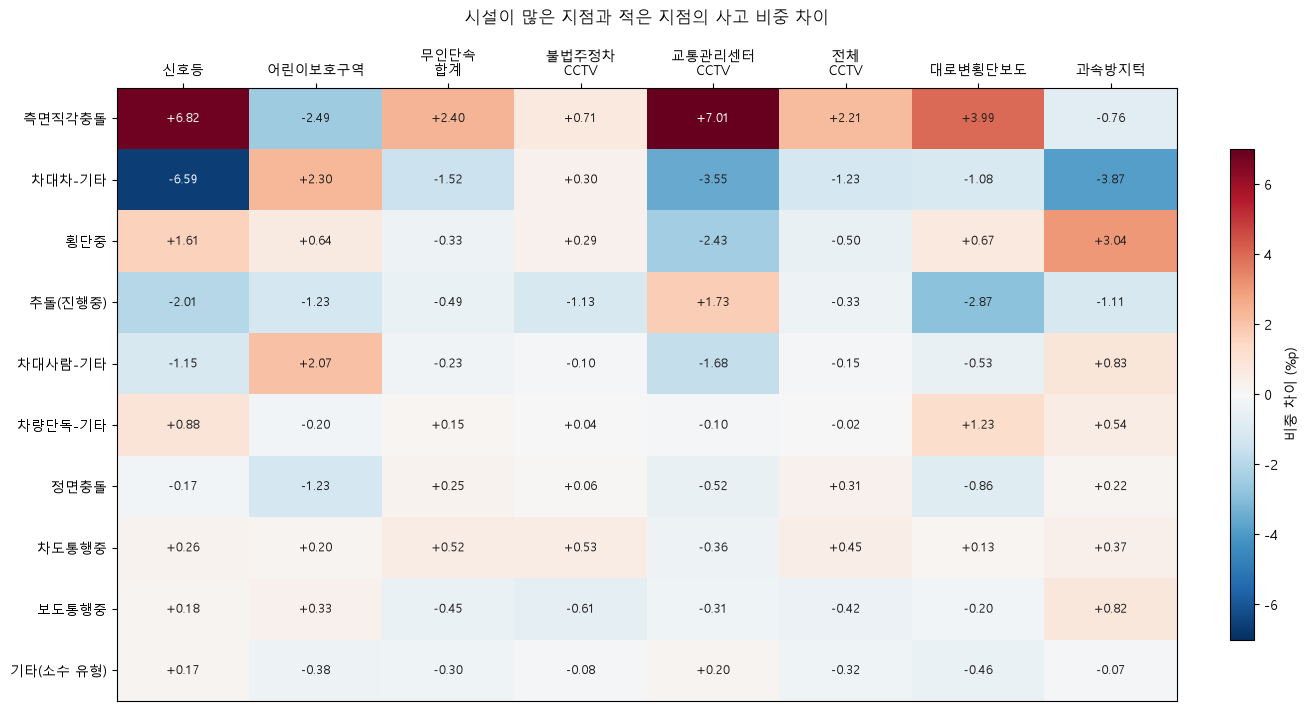

In [10]:
fonts = {f.name for f in font_manager.fontManager.ttflist}
for family in ["Malgun Gothic", "Apple SD Gothic Neo", "NanumGothic", "Noto Sans CJK KR"]:
    if family in fonts:
        plt.rcParams["font.family"] = family
        break
plt.rcParams["axes.unicode_minus"] = False

subtype_order = events[grouped_col].value_counts().index
matrix = detail["차이(%p)"].unstack("시설").loc[subtype_order, facilities]
limit = max(1, np.abs(matrix.to_numpy()).max())
fig, ax = plt.subplots(figsize=(13, 7), layout="constrained")
heat = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
axis_labels = {"무인단속 합계": "무인단속\n합계", "불법주정차 CCTV": "불법주정차\nCCTV",
               "교통관리센터 CCTV": "교통관리센터\nCCTV", "전체 CCTV": "전체\nCCTV"}
ax.set_xticks(range(len(facilities)), [axis_labels.get(name, name) for name in facilities])
ax.set_yticks(range(len(matrix)), matrix.index)
ax.xaxis.tick_top()
ax.set_title("시설이 많은 지점과 적은 지점의 사고 비중 차이", pad=18)
for row, values in enumerate(matrix.to_numpy()):
    for col, value in enumerate(values):
        color = "white" if abs(value) > limit * 0.62 else "#202020"
        ax.text(col, row, f"{value:+.2f}", ha="center", va="center", color=color, fontsize=9)
fig.colorbar(heat, ax=ax, shrink=0.8, label="비중 차이 (%p)")
plt.show()

## 8. 결과 읽기 — 여덟 시설 지표 한눈에 보기

서울 사고누적지점 327곳의 2023~2025년 사망·중상사고 4,564건을 비교했다. 표에는 반경 1 km 안의 각 시설에 대해 **‘많음 − 적음’의 비중 차이가 가장 큰 세부유형**을 하나씩 담았다. 각 비중의 분모는 해당 구간에서 발생한 전체 사고 건수다. 아래 셀은 6단계에서 소수 유형을 묶은 뒤 구한 시설별 최댓값 행을 발표 순서대로 표시한다.

In [11]:
presentation = largest[[*levels, "차이(%p)"]].rename_axis(index=["시설", "세부유형"])
percent_formats = {level: "{:.2f}%" for level in levels}
display(presentation.style.format({**percent_formats, "차이(%p)": "{:+.2f}%p"}))

# 소수 유형을 묶기 전·후에 차이 1위가 달라지는지 확인한다.
original_detail = compare_types(detail_col)
original_rows = original_detail.groupby(level="시설")["차이(%p)"].idxmax()
before_grouping = dict(original_rows.tolist())
after_grouping = dict(largest.index)
changes = [f"{name}({before_grouping[name]} → {after_grouping[name]})" for name in facilities
           if before_grouping[name] != after_grouping[name]]
if changes:
    print(f"전체 사고의 {min_share_pct:g}% 미만 유형을 묶은 뒤 1위가 달라진 지표", ", ".join(changes))
else:
    print(f"전체 사고의 {min_share_pct:g}% 미만 유형을 묶기 전과 후, {len(facilities)}개 시설 지표 모두 비중 차이 1위가 같았다.")

,구간,적음,중간,많음,차이(%p)
시설,세부유형,,,,
신호등,측면직각충돌,25.41%,28.47%,32.22%,+6.82%p
어린이보호구역,차대차-기타,24.36%,25.38%,26.66%,+2.30%p
무인단속 합계,측면직각충돌,27.43%,29.26%,29.82%,+2.40%p
불법주정차 CCTV,측면직각충돌,27.89%,30.06%,28.60%,+0.71%p
교통관리센터 CCTV,측면직각충돌,27.01%,27.94%,34.02%,+7.01%p
전체 CCTV,측면직각충돌,27.52%,29.11%,29.73%,+2.21%p
대로변횡단보도,측면직각충돌,27.82%,26.81%,31.81%,+3.99%p
과속방지턱,횡단중,11.10%,12.53%,14.15%,+3.04%p


전체 사고의 1% 미만 유형을 묶기 전과 후, 8개 시설 지표 모두 비중 차이 1위가 같았다.


In [12]:
# 비중의 분모는 해당 시설 구간에서 발생한 전체 사고 건수다.
for facility in ["무인단속 합계", "불법주정차 CCTV", "교통관리센터 CCTV", "전체 CCTV"]:
    subtype = after_grouping[facility]
    row = detail.loc[(facility, subtype)]
    print(f"{facility} · 비중 차이 1위는 {subtype} ({row['차이(%p)']:+.2f}%p)")
    for level in levels:
        total = group_sizes.loc[(facility, level), "사고건수"]
        print(f"  {level} · {int(row[level + ' 건수'])}/{total}건 ({row[level]:.2f}%)")

무인단속 합계 · 비중 차이 1위는 측면직각충돌 (+2.40%p)
  적음 · 435/1586건 (27.43%)
  중간 · 421/1439건 (29.26%)
  많음 · 459/1539건 (29.82%)
불법주정차 CCTV · 비중 차이 1위는 측면직각충돌 (+0.71%p)
  적음 · 434/1556건 (27.89%)
  중간 · 428/1424건 (30.06%)
  많음 · 453/1584건 (28.60%)
교통관리센터 CCTV · 비중 차이 1위는 측면직각충돌 (+7.01%p)
  적음 · 731/2706건 (27.01%)
  중간 · 221/791건 (27.94%)
  많음 · 363/1067건 (34.02%)
전체 CCTV · 비중 차이 1위는 측면직각충돌 (+2.21%p)
  적음 · 409/1486건 (27.52%)
  중간 · 427/1467건 (29.11%)
  많음 · 479/1611건 (29.73%)


**전체 CCTV 발표 요약**

대분류와 세부유형에서 ‘많음 − 적음’ 차이가 가장 큰 항목을 각각 읽는다. 세 구간의 비중을 함께 보면 중간 구간에서도 같은 방향으로 변했는지 확인할 수 있다.

In [13]:
for group_name, table in [("대분류", major), ("세부유형", detail)]:
    total_cctv = table.loc["전체 CCTV"]
    top_type = total_cctv["차이(%p)"].idxmax()
    row = total_cctv.loc[top_type]
    shares = " → ".join(f"{row[level]:.2f}%" for level in levels)
    trend = " / 두 단계 모두 상승" if row["두 단계 모두 상승"] else ""
    print(f"{group_name} · {top_type} · {shares} · 많음−적음 {row['차이(%p)']:+.2f}%p{trend}")

대분류 · 차대차 · 68.17% → 67.89% → 68.84% · 많음−적음 +0.67%p
세부유형 · 측면직각충돌 · 27.52% → 29.11% → 29.73% · 많음−적음 +2.21%p / 두 단계 모두 상승


**발표할 때 짚을 점**

- **신호등**이 많은 지점으로 갈수록 차대차 전체 비중은 69.51%에서 67.59%로 낮아졌지만, 그중 측면직각충돌이 전체 사고에서 차지하는 비중은 세 구간에서 차례로 높아졌다.
- **어린이보호구역** 대상시설 수로 나눴을 때 차대사람 사고 비중은 23.71% → 29.49% → 26.81%로 **중간 구간에서 가장 높았다**. 이 수치에는 모든 연령의 보행자가 포함된다.
- **대로변횡단보도** 링크가 많은 지점에서 측면직각충돌 비중이 가장 높았지만, 중간 구간에서는 한 번 낮아졌다. 차대사람 사고 비중은 세 구간 모두 26%대로 비슷했다.
- **과속방지턱**이 적은·중간·많은 지점 순으로 차대사람 사고 비중은 23.43% → 27.12% → 28.55%로 높아졌다. 보행자가 횡단하던 중 발생한 사고도 같은 순서로 비중이 높아졌다.

이 결과는 해당 지점에서 관측한 **사망·중상사고의 유형 구성**을 보여준다. 시설 조사 시점과 사고 시점이 다를 수 있고 통행량·보행량·도로 구조를 통제하지 않았으므로, 시설 설치 효과나 통행 한 건당 사고 확률을 이 표로 추정할 수 없다.

불법주정차 CCTV는 고정형 단속지점 수이며, 교통관리센터 CCTV는 도로 소통 관제 장비 수다. 전체 CCTV에는 두 용도가 함께 반영된다. 시설 자료의 기준 시점과 도로 환경도 함께 고려한다.